# 3 Prediction

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

%load_ext autoreload
%autoreload 2

from a02_helper import *
from a02_functions import gd_er, predict, classify, optimize, sgd_er, er

In [2]:
# Fitted model
np.random.seed(0)
w0 = np.random.normal(size=D)
wz_gd, vz_gd, ez_gd = optimize(gd_er(y, Xz), w0, nepochs=500)

Epoch   0: f=     2.165, eps=0.010000000
Epoch   1: f=     2.161, eps=0.010500000
Epoch   2: f=     2.157, eps=0.011025000
Epoch   3: f=     2.153, eps=0.011576250
Epoch   4: f=     2.148, eps=0.012155063
Epoch   5: f=     2.143, eps=0.012762816
Epoch   6: f=     2.138, eps=0.013400956
Epoch   7: f=     2.133, eps=0.014071004
Epoch   8: f=     2.128, eps=0.014774554
Epoch   9: f=     2.122, eps=0.015513282
Epoch  10: f=     2.116, eps=0.016288946
Epoch  11: f=     2.110, eps=0.017103394
Epoch  12: f=     2.104, eps=0.017958563
Epoch  13: f=     2.098, eps=0.018856491
Epoch  14: f=     2.091, eps=0.019799316
Epoch  15: f=     2.084, eps=0.020789282
Epoch  16: f=     2.076, eps=0.021828746
Epoch  17: f=     2.069, eps=0.022920183
Epoch  18: f=     2.061, eps=0.024066192
Epoch  19: f=     2.052, eps=0.025269502
Epoch  20: f=     2.044, eps=0.026532977
Epoch  21: f=     2.035, eps=0.027859626
Epoch  22: f=     2.025, eps=0.029252607
Epoch  23: f=     2.016, eps=0.030715238
Epoch  24: f=   

In `a02_functions.py`, complete the `predict` and `classify` methods for the predicted
spam probability and predicted class label, respectively. Use them to explore your
previously fitted model.

In [3]:
# Exploration example: confusion matrix
yhat = predict(Xtestz, wz_gd)
ypred = classify(Xtestz, wz_gd)
print(sklearn.metrics.confusion_matrix(ytest, ypred))  # true x predicted

[[887  54]
 [ 71 524]]


In [4]:
# Exploration example: classification report
print(sklearn.metrics.classification_report(ytest, ypred))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93       941
           1       0.91      0.88      0.89       595

    accuracy                           0.92      1536
   macro avg       0.92      0.91      0.91      1536
weighted avg       0.92      0.92      0.92      1536



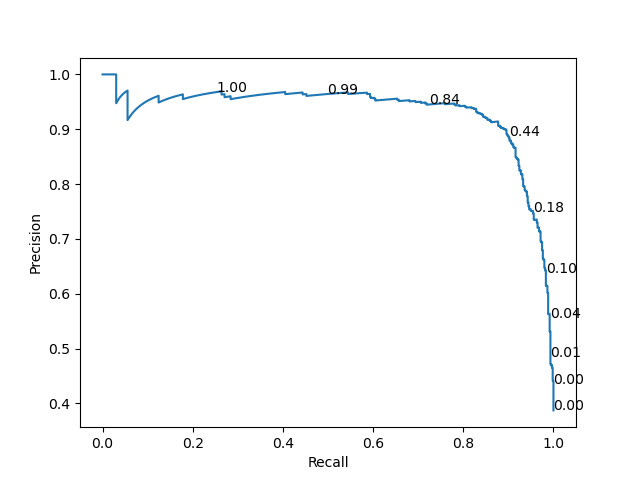

In [5]:
# Exploration Example: precision-recall curve (with annotated thresholds)
nextplot()
precision, recall, thresholds = sklearn.metrics.precision_recall_curve(ytest, yhat)
plt.plot(recall, precision)
for x in np.linspace(0, 1, 10, endpoint=False):
    index = int(x * (precision.size - 1))
    plt.text(recall[index], precision[index], "{:3.2f}".format(thresholds[index]))
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()


GD evaluation
Accuracy: 0.9186197916666666
Mean test log loss: 0.279154987545378
Confusion matrix (rows=true, columns=predicted):
[[887  54]
 [ 71 524]]
              precision    recall  f1-score   support

           0     0.9259    0.9426    0.9342       941
           1     0.9066    0.8807    0.8934       595

    accuracy                         0.9186      1536
   macro avg     0.9162    0.9116    0.9138      1536
weighted avg     0.9184    0.9186    0.9184      1536


SGD evaluation
Accuracy: 0.9173177083333334
Mean test log loss: 0.28274012548135574
Confusion matrix (rows=true, columns=predicted):
[[886  55]
 [ 72 523]]
              precision    recall  f1-score   support

           0     0.9248    0.9416    0.9331       941
           1     0.9048    0.8790    0.8917       595

    accuracy                         0.9173      1536
   macro avg     0.9148    0.9103    0.9124      1536
weighted avg     0.9171    0.9173    0.9171      1536



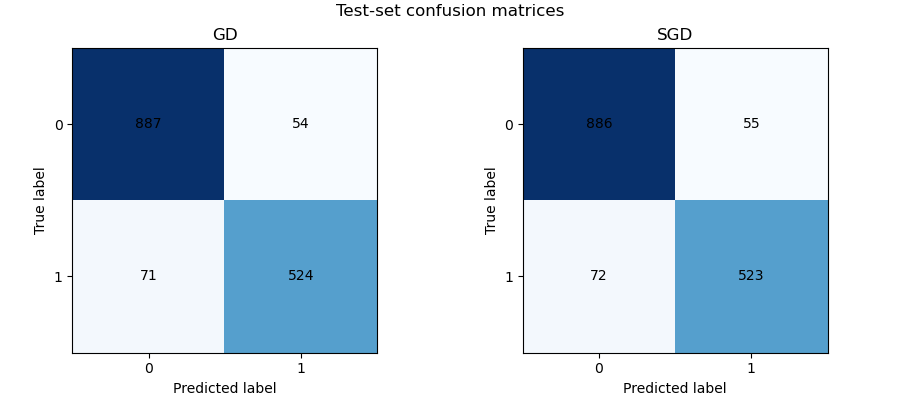

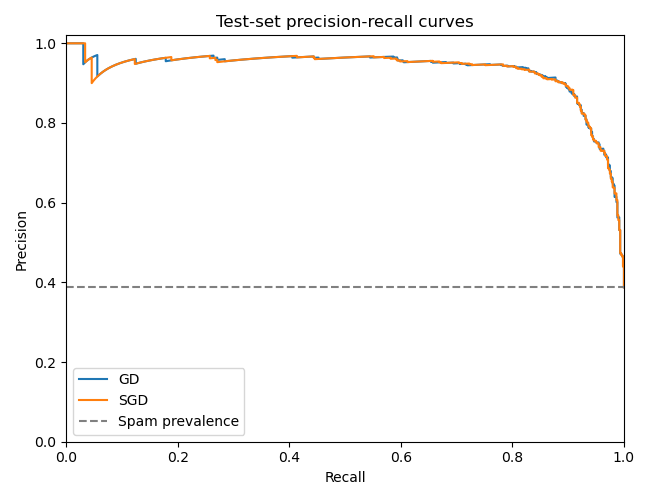

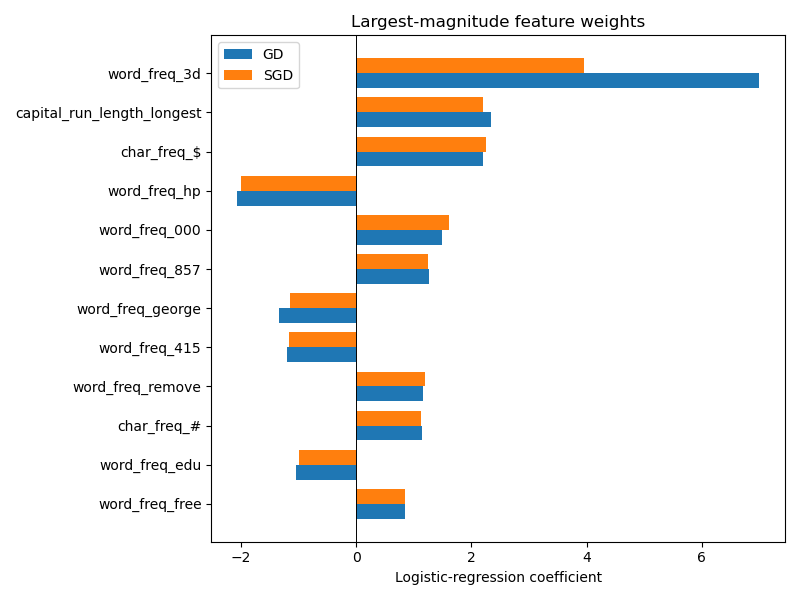

Largest-magnitude features:
                            GD weight  SGD weight  mean absolute weight
word_freq_3d                   6.9897      3.9553                5.4725
capital_run_length_longest     2.3443      2.2032                2.2738
char_freq_$                    2.2043      2.2539                2.2291
word_freq_hp                  -2.0623     -2.0059                2.0341
word_freq_000                  1.4938      1.6087                1.5512
word_freq_857                  1.2697      1.2414                1.2556
word_freq_george              -1.3452     -1.1463                1.2458
word_freq_415                 -1.2001     -1.1603                1.1802
word_freq_remove               1.1615      1.1914                1.1764
char_freq_#                    1.1491      1.1252                1.1372
word_freq_edu                 -1.0375     -0.9961                1.0168
word_freq_free                 0.8452      0.8519                0.8485
Smallest-magnitude features:
       

In [6]:
# Explore which features are considered important
# YOUR CODE HERE
# Fit the second model from Task 2 with the same initialization.
np.random.seed(0)
w0_sgd = np.random.normal(size=D)
wz_sgd, vz_sgd, ez_sgd = optimize(sgd_er(y, Xz), w0_sgd, nepochs=500, verbose=False)

task3_models = {"GD": wz_gd, "SGD": wz_sgd}
task3_probabilities = {name: predict(Xtestz, w) for name, w in task3_models.items()}
task3_labels = {name: classify(Xtestz, w) for name, w in task3_models.items()}

for name in task3_models:
    print(f"\n{name} evaluation")
    print("Accuracy:", sklearn.metrics.accuracy_score(ytest, task3_labels[name]))
    print("Mean test log loss:", er(ytest, Xtestz, task3_models[name]))
    print("Confusion matrix (rows=true, columns=predicted):")
    print(sklearn.metrics.confusion_matrix(ytest, task3_labels[name], labels=[0, 1]))
    print(sklearn.metrics.classification_report(ytest, task3_labels[name], labels=[0, 1], digits=4, zero_division=0))

from pathlib import Path
task3_results = Path("../results/task3")
task3_results.mkdir(parents=True, exist_ok=True)

# Compare test-set confusion matrices for the two Task 2 models.
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, (name, labels_hat) in zip(axes, task3_labels.items()):
    matrix = sklearn.metrics.confusion_matrix(ytest, labels_hat, labels=[0, 1])
    image = ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]}", ha="center", va="center")
    ax.set(title=name, xlabel="Predicted label", ylabel="True label", xticks=[0, 1], yticks=[0, 1])
fig.suptitle("Test-set confusion matrices")
fig.savefig(task3_results / "confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

# Compare precision-recall curves using the test-set spam probabilities.
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, probabilities in task3_probabilities.items():
    precision, recall, _ = sklearn.metrics.precision_recall_curve(ytest, probabilities)
    ax.plot(recall, precision, label=name)
ax.axhline(np.mean(ytest), linestyle="--", color="gray", label="Spam prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Test-set precision-recall curves", xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
fig.savefig(task3_results / "precision_recall.png", dpi=180, bbox_inches="tight")
plt.show()

# Save the numerical evaluation alongside the plots for reproducibility.
with (task3_results / "metrics.txt").open("w", encoding="utf-8") as output:
    for name in task3_models:
        output.write(f"{name}\n")
        output.write(f"accuracy={sklearn.metrics.accuracy_score(ytest, task3_labels[name]):.8f}\n")
        output.write(f"mean_test_log_loss={er(ytest, Xtestz, task3_models[name]):.8f}\n")
        output.write("confusion_matrix_rows_true_columns_predicted:\n")
        output.write(str(sklearn.metrics.confusion_matrix(ytest, task3_labels[name], labels=[0, 1])) + "\n")
        output.write(sklearn.metrics.classification_report(ytest, task3_labels[name], labels=[0, 1], digits=4, zero_division=0))
        output.write("\n")

# Compare the signed coefficients by their average absolute magnitude.
importance = np.mean(np.abs(np.vstack([wz_gd, wz_sgd])), axis=0)
top = np.argsort(importance)[-12:]
top = top[np.argsort(importance[top])]
fig, ax = plt.subplots(figsize=(8, 6))
positions = np.arange(len(top))
height = 0.38
ax.barh(positions - height / 2, wz_gd[top], height, label="GD")
ax.barh(positions + height / 2, wz_sgd[top], height, label="SGD")
ax.set(yticks=positions, yticklabels=features[top], xlabel="Logistic-regression coefficient", title="Largest-magnitude feature weights")
ax.axvline(0, color="black", linewidth=0.7)
ax.legend()
fig.tight_layout()
fig.savefig(task3_results / "feature_weights.png", dpi=180, bbox_inches="tight")
plt.show()

weight_table = pd.DataFrame({"GD weight": wz_gd, "SGD weight": wz_sgd}, index=features)
weight_table["mean absolute weight"] = importance
weight_table.to_csv(task3_results / "feature_weights.csv")
print("Largest-magnitude features:")
print(weight_table.reindex(weight_table["mean absolute weight"].nlargest(12).index).round(4).to_string())
print("Smallest-magnitude features:")
print(weight_table.reindex(weight_table["mean absolute weight"].nsmallest(8).index).round(4).to_string())